**Creating BIAS and FLATS**

In [10]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from astropy.io import fits
import os

Master BIAS -> is just meridian of each pixel

In [11]:
bias_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data\bias\\"
bias_files = os.listdir(bias_dir) #all files in directory
bias_images = [] #array that contains all bias images

for file in bias_files: #which datasets?
    image = fits.getdata(bias_dir+file)
    bias_images.append(image)

# Stack the Bias images using median
master_bias = np.median(np.asarray(bias_images), axis=0) #meridian is less sensitive to outliers

#save the master bias as fits file

savename = r"C:\Users\jw141\Desktop\astrolab_observations\\" + "master_bias.fits"
fits.writeto(savename, master_bias, overwrite=True)


MASTER FLAT - for each filter

In [25]:
flat_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data\flats\\"
flat_files = os.listdir(flat_dir) #all files in directory
flat_images = [] #array that contains all bias images

filters = ["black","green","red","blue"]


for file in flat_files[-129:-99]: #which datasets?
    image = fits.getdata(flat_dir+file)
    flat_images.append(image)

#blacks = flat_files[-30:]
#red = flat_files[-65:-35]
#green = flat_files[-97:-67]
#blue = flat_files[-129:-99]

if True:
    # Stack the flat images
    cflats = []
    for ic in range(len(flat_images)):
        cflats.append((flat_images[ic] - master_bias)/np.median(flat_images[ic]-master_bias))
    master_flat = np.median(cflats,axis=0)

    #save the master flat
    fits.writeto(r"C:\Users\jw141\Desktop\astrolab_observations\\"+"master_flat_blue.fits", master_flat, overwrite=True)


['Flat_2025-09-15_18-33-59_Blue_0064.fits', 'Flat_2025-09-15_18-34-37_Blue_0065.fits', 'Flat_2025-09-15_18-35-32_Blue_0066.fits', 'Flat_2025-09-15_18-35-34_Blue_0067.fits', 'Flat_2025-09-15_18-35-37_Blue_0068.fits', 'Flat_2025-09-15_18-35-40_Blue_0069.fits', 'Flat_2025-09-15_18-35-43_Blue_0070.fits', 'Flat_2025-09-15_18-35-45_Blue_0071.fits', 'Flat_2025-09-15_18-35-48_Blue_0072.fits', 'Flat_2025-09-15_18-35-51_Blue_0073.fits', 'Flat_2025-09-15_18-35-54_Blue_0074.fits', 'Flat_2025-09-15_18-35-56_Blue_0075.fits', 'Flat_2025-09-15_18-35-59_Blue_0076.fits', 'Flat_2025-09-15_18-36-02_Blue_0077.fits', 'Flat_2025-09-15_18-36-05_Blue_0078.fits', 'Flat_2025-09-15_18-36-07_Blue_0079.fits', 'Flat_2025-09-15_18-36-10_Blue_0080.fits', 'Flat_2025-09-15_18-36-13_Blue_0081.fits', 'Flat_2025-09-15_18-36-16_Blue_0082.fits', 'Flat_2025-09-15_18-36-18_Blue_0083.fits', 'Flat_2025-09-15_18-36-21_Blue_0084.fits', 'Flat_2025-09-15_18-36-24_Blue_0085.fits', 'Flat_2025-09-15_18-36-27_Blue_0086.fits', 'Flat_2025

In [29]:
flat_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data\flats\\"
flat_files = os.listdir(flat_dir) #all files in directory

master_flat_dir = {}


#different filters
filters = ["black","green","red","blue"]
flat_files_dict = {"black":flat_files[-30:],"green":flat_files[-97:-67],"red":flat_files[-65:-35],"blue":flat_files[-129:-99]}

for filter in filters:
    flat_images = [] #array that contains all bias images
    for file in flat_files_dict[filter]: #which datasets?
        image = fits.getdata(flat_dir+file)
        flat_images.append(image)

    # Stack the flat images after normalizing to the median
    cflats = []
    for ic in range(len(flat_images)):
        cflats.append((flat_images[ic] - master_bias)/np.median(flat_images[ic]-master_bias))
    master_flat = np.median(cflats,axis=0)
    master_flat_dir[filter] = master_flat

    #save the master flat
    fits.writeto(r"C:\Users\jw141\Desktop\astrolab_observations\\"+"master_flat_"+filter+".fits", master_flat, overwrite=True)







Plot MASTER BIAS AND MASTER FLAT

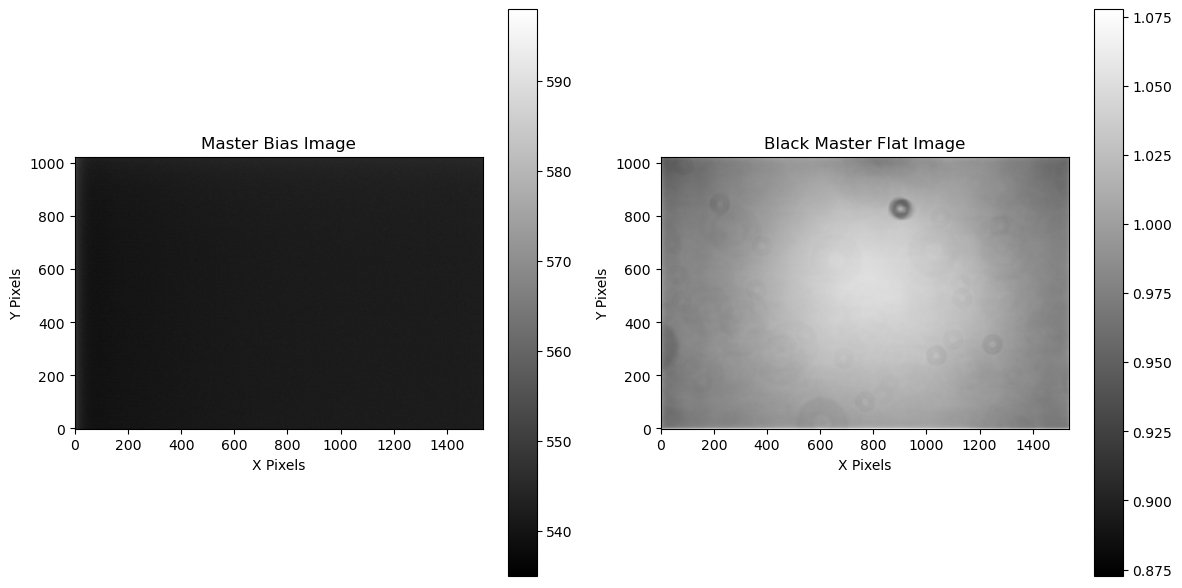

In [34]:
# Create a single figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))  # 1 row, 2 columns of subplots

# Plot the master bias in the first subplot
im1 = ax1.imshow(master_bias, cmap='gray', origin='lower')
ax1.set_title('Master Bias Image')
ax1.set_xlabel('X Pixels')
ax1.set_ylabel('Y Pixels')
fig.colorbar(im1, ax=ax1)  # Use fig.colorbar with the corresponding axis

# Plot the master flat in the second subplot
im2 = ax2.imshow(master_flat_dir["green"], cmap='gray', origin='lower')
ax2.set_title('Black Master Flat Image')
ax2.set_xlabel('X Pixels')
ax2.set_ylabel('Y Pixels')
fig.colorbar(im2, ax=ax2)  # Use fig.colorbar with the corresponding axis

plt.tight_layout()  # Ensure proper spacing between subplots
plt.show()